<a href="https://colab.research.google.com/github/ibader85/PredictiveAnalytics/blob/main/28_Association_Rules_Using_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

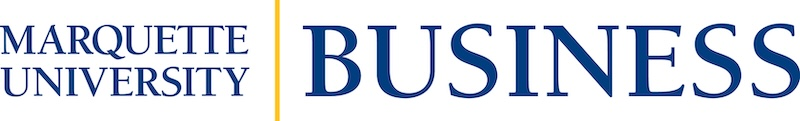

# BUAN 3065: Unlocking Business Insights with Predictive Analytics
# Association Rules Using Python

Instructor: Dr. Badar Al Lawati

**Disclaimer:** the content in this notebook is based on the content in Chapter 14 of Business Analytics by Sanjiv Jaggia, Alison Kelly, Kevin Lertwachara and Leida Chen. ISBN10: 126692602X | ISBN13: 9781266926020

**Problem:** The store manager at an electronics store collects data on the last 100 transactions.

Five possible products were purchased: a keyboard, an SD card, a mouse, a USB drive, and/or a headphone

In [2]:
# Import the dataset

import pandas as pd
myData = pd.read_csv('/content/Transaction.csv', header = None)
myData.head()

,0,1,2,3,4
0,keyboard,mouse,headphone,NaN,NaN
1,keyboard,SDcard,mouse,NaN,NaN
2,headphone,NaN,NaN,NaN,NaN
3,keyboard,NaN,NaN,NaN,NaN
4,keyboard,SDcard,mouse,USBdrive,NaN


We convert the data into a list structure where each element is a
transaction without null values (NaN).

The part of the code, “for
transaction in myData.values,” iterates through each element
(transaction) in “myData.values.”

The part of the code,
“transaction[~pd.isnull(transaction)],” applies a filter to remove
the null (NaN) values from the transaction array, leaving only the
non-null elements

In [3]:
Transactions = [transaction[~pd.isnull(transaction)] for transaction in myData.values]
Transactions[:5]

[array(['keyboard', 'mouse', 'headphone'], dtype=object),
 array(['keyboard', 'SDcard', 'mouse'], dtype=object),
 array(['headphone'], dtype=object),
 array(['keyboard'], dtype=object),
 array(['keyboard', 'SDcard', 'mouse', 'USBdrive'], dtype=object)]

We convert the transactions into a binary format that is suitable
for analysis. We use the *Mlxtend* library to perform the data
preprocessing

In [4]:
%pip install mlxtend

Let's import the TransactionEncoder class from the Mlxtend
library and create a variable of the class named encoder.

We then
use the fit_transform function to convert the transaction data into
a binary format and save the result in a variable named
Transactions_Encoded.

Each row in Transactions_Encoded
represents a transaction, and each column corresponds to an item
(i.e., keyboard, mouse, headphone, SDcard, or USBdrive).

If an
item is present in a transaction, the corresponding cell is set to
True; otherwise, it is set to False.

Finally, we convert
Transactions_Encoded into a Pandas DataFrame named
Transactions_df for ease of manipulation in the subsequent steps

In [5]:
from mlxtend.preprocessing import TransactionEncoder
encoder = TransactionEncoder()

Transactions_Encoded = encoder.fit_transform(Transactions)

Transactions_df = pd.DataFrame(Transactions_Encoded, columns = encoder.columns_)

Transactions_df.head()

,SDcard,USBdrive,headphone,keyboard,mouse
0,False,False,True,True,True
1,True,False,False,True,True
2,False,False,True,False,False
3,False,False,False,True,False
4,True,True,False,True,True


In [6]:
# To compute the frequency or support for each item, we divide the
# sum of each column of Transactions_df by the total number of
# transactions in the dataset

Transactions_df.sum() / len(Transactions_df)

,0
SDcard,0.62
USBdrive,0.19
headphone,0.32
keyboard,0.67
mouse,0.49


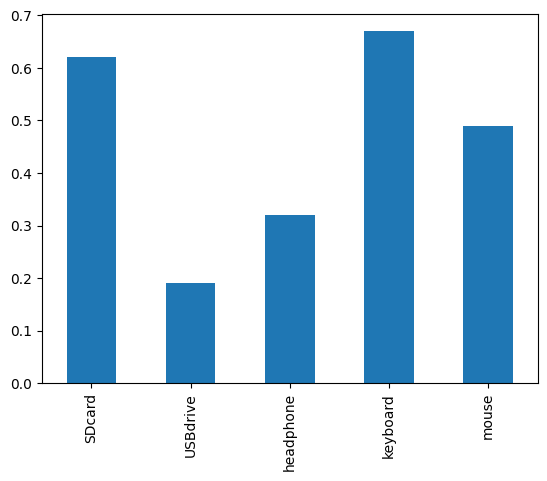

In [7]:
# To visualize the item frequencies, we plot the item frequency plot

(Transactions_df.sum() / len(Transactions_df)).plot.bar();

In [8]:
# To conduct the association rule analysis, we use the Efficient-Apriori package

%pip install efficient-apriori

We use the apriori function to discover frequent itemsets and association rules in the transaction data.

The first option of the function refers to the list, Transactions. We set minimum values of support and confidence at 0.1 and 0.5, respectively.

Practitioners usually experiment with different support and confidence thresholds to see whether or not interesting results might emerge.

The apriori function returns two objects, itemsets and rules. Itemsets contain the frequent itemsets found in the transactions, and rules contain the association rules generated from the frequent itemsets.

In [9]:
from efficient_apriori import apriori

itemsets, rules = apriori(Transactions, min_support = 0.1, min_confidence = 0.5)

In [11]:
# We create a data frame that contains the various attributes of the rules object including rule,
# confidence, support, lift, and count. We sort the rules by the lift values

Rules = pd. DataFrame ({'Rule': [rule.__repr__() for rule in rules], 'Confidence': [rule.confidence for rule in rules], 'Support': [rule.support for rule in rules], 'Lift': [rule. lift for rule in rules], 'Count':[rule.count_full for rule in rules]})

Rules. sort_values('Lift', ascending = False)

,Rule,Confidence,Support,Lift,Count
0,{keyboard} -> {SDcard},0.820896,0.55,1.324025,55
1,{SDcard} -> {keyboard},0.887097,0.55,1.324025,55
8,"{SDcard, mouse} -> {keyboard}",0.884615,0.23,1.320321,23
7,"{keyboard, mouse} -> {SDcard}",0.793103,0.23,1.279199,23
5,"{headphone, keyboard} -> {SDcard}",0.785714,0.11,1.267281,11
6,"{SDcard, headphone} -> {keyboard}",0.785714,0.11,1.172708,11
4,{mouse} -> {keyboard},0.591837,0.29,0.883338,29
3,{USBdrive} -> {keyboard},0.578947,0.11,0.864101,11
2,{mouse} -> {SDcard},0.530612,0.26,0.855826,26


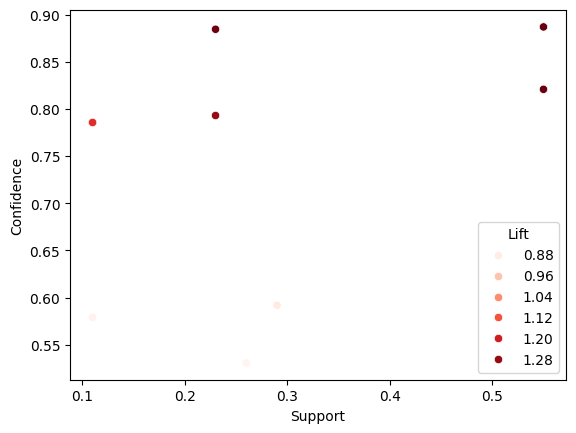

In [12]:
# The scatterplot makes it easy to identify the rules with high lift ratios, confidence values, and support values

import seaborn as sns
sns.scatterplot(x = 'Support', y = 'Confidence', hue = 'Lift', data = Rules, palette = 'Reds');